In [53]:
import pandas as pd
import networkx as nx
import numpy as np
from collections import Counter

In [32]:
data = pd.read_csv('data/data_filtered.tsv', sep='\t', index_col=0)

In [40]:
# drop nodes that will be duplicates if we are to consider the network as undirected

undirected = pd.DataFrame(
    np.sort(data[['From Verse', 'To Verse']].values, axis=1),
    columns=['verse1', 'verse2'],
    index=data.index
)
undirected['Votes'] = data['Votes']
undirected.drop_duplicates(inplace=True)

In [42]:
undirected

,verse1,verse2,Votes
0,Exod.20.11,Gen.1.1,154
1,Gen.1.1,Jer.51.15,89
2,Gen.1.1,Heb.1.10,190
3,Gen.1.1,Ps.121.2,65
4,Gen.1.1,Ps.115.15,82
...,...,...,...
344749,Rev.1.4,Rev.22.21,2
344750,2Thess.3.18,Rev.22.21,10
344752,Eph.6.23-Eph.6.24,Rev.22.21,2
344754,2Cor.13.14,Rev.22.21,7


# Analysis

In [46]:
G = nx.from_pandas_edgelist(
    data, 
    source='From Verse', 
    target='To Verse', 
    edge_attr='Votes',
    create_using=nx.DiGraph()
)

In [ ]:
#statistics
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
density = nx.density(G)
degrees = [deg for node, deg in G.degree()]
avg_degree = sum(degrees) / len(degrees)
degree_distribution = Counter(degrees)
degree_centrality = nx.degree_centrality(G)
closeness_centrality = nx.closeness_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G)

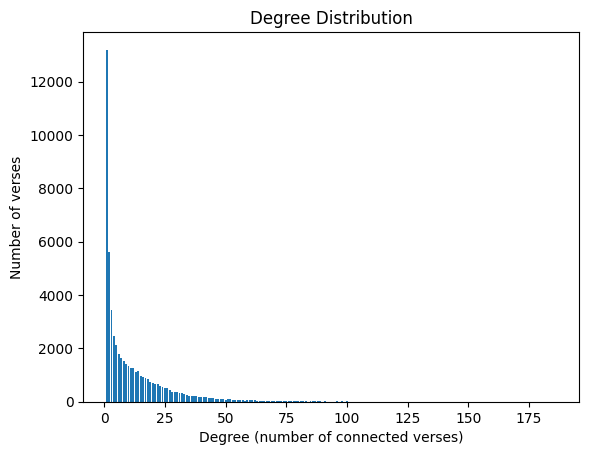

In [64]:
import matplotlib.pyplot as plt

labels, values = zip(*degree_distribution.items())

plt.bar(labels, values)

plt.xlabel('Degree (number of connected verses)')
plt.ylabel('Number of verses')
plt.title('Degree Distribution')

plt.show()